In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import string
from plotters import plot_differentiation_tree

In [4]:
diff_T = nx.DiGraph()

diff_T.add_node("A", diff_time=None)

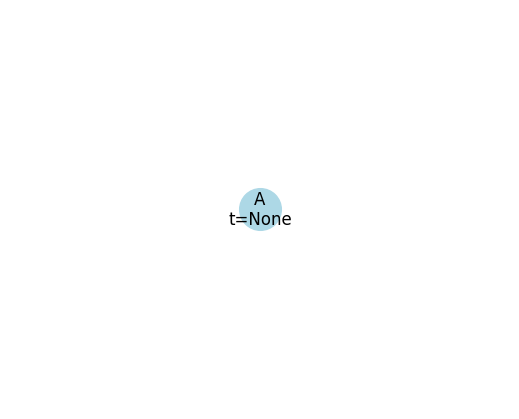

In [5]:
plot_differentiation_tree(diff_T)
# plt.show()

In [6]:
from simulator import load_tree

In [7]:
T, root = load_tree("../data/simulation/test/T_extant.json")

In [8]:
for u, v, data in T.edges(data=True):
    print(f"{u} -> {v} : {data}")

0 -> 2 : {'start_time': 0.0, 'end_time': 0.436873164847313, 'length': 0.436873164847313}
2 -> 4 : {'start_time': 0.436873164847313, 'end_time': 0.6326093695318391, 'length': 0.19573620468452613}
2 -> 5 : {'start_time': 0.436873164847313, 'end_time': 0.7322208355578844, 'length': 0.29534767071057144}
4 -> 8 : {'start_time': 0.6326093695318391, 'end_time': 0.7063669602325849, 'length': 0.07375759070074583}
4 -> 15 : {'start_time': 0.6326093695318391, 'end_time': 1.0, 'length': 0.3673906304681609}
5 -> 12 : {'start_time': 0.7322208355578844, 'end_time': 0.8868204428435476, 'length': 0.15459960728566313}
5 -> 13 : {'start_time': 0.7322208355578844, 'end_time': 0.7917608958446912, 'length': 0.059540060286806806}
8 -> 10 : {'start_time': 0.7063669602325849, 'end_time': 1.0, 'length': 0.29363303976741506}
8 -> 11 : {'start_time': 0.7063669602325849, 'end_time': 1.0, 'length': 0.29363303976741506}
12 -> 20 : {'start_time': 0.8868204428435476, 'end_time': 0.9941796730963411, 'length': 0.1073592

In [9]:
cell_lineage_T = nx.DiGraph()

for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])
    if 'end_time' in data and data['end_time'] == 1:
        cell_lineage_T.nodes[v]['type'] = "A"

In [10]:
from plotters import draw_ultrametric_tree

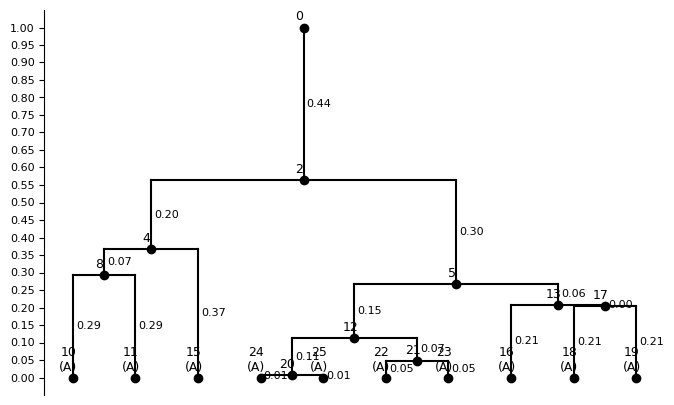

In [11]:
draw_ultrametric_tree(cell_lineage_T, root=root, diff_T=diff_T)

In [12]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [13]:
from likelihood import type_internal_nodes

In [14]:
cell_lineage_T = type_internal_nodes(cell_lineage_T, diff_T)

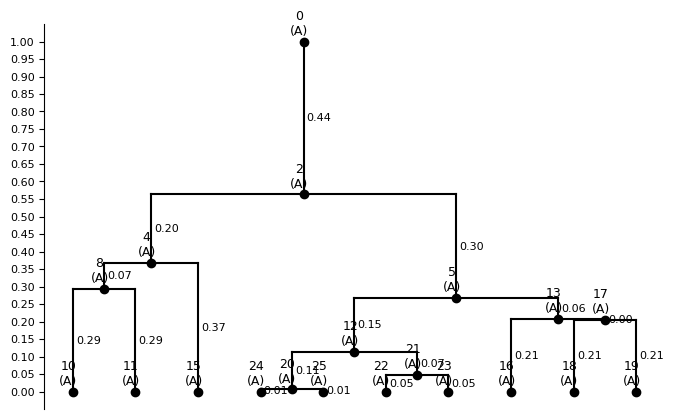

In [15]:
draw_ultrametric_tree(cell_lineage_T, root=0, diff_T=diff_T)

In [43]:
from likelihood import calculate_likelihood_of_tree, calculate_likelihood_2

In [59]:
birth_rates = {"A": 1.5}
death_rates = {"A": 0.001}

p1 = calculate_likelihood_of_tree(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_rate=1.0,
    transition_probabilities=None,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)
print('='*50)
p2 = calculate_likelihood_2(
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=None,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)

print(p1, p2)

0.3831172591805509 0.3831172591805509


In [60]:
import numpy as np


def likelihood_grid(
    birth_grid,
    death_grid,
    cell_lineage_T,
    diff_T
):
    """
    Compute likelihoods over a grid of birth/death rates.
    """

    L = np.zeros((len(death_grid), len(birth_grid)))

    for i, lam in enumerate(birth_grid):
        for j, mu in enumerate(death_grid):
            birth_rates = {"A": lam}
            death_rates = {"A": mu}

            L[j, i] = calculate_likelihood_of_tree(
                birth_rates=birth_rates,
                death_rates=death_rates,
                sampling_rate=1,
                transition_probabilities=None,
                cell_lineage_T=cell_lineage_T,
                diff_T=diff_T
            )

    return L


In [61]:
import matplotlib.pyplot as plt


def plot_likelihood_surface(birth_grid, death_grid, L):
    plt.figure(figsize=(6, 5))

    plt.imshow(
        L,
        origin="lower",
        extent=[
            birth_grid.min(), birth_grid.max(),
            death_grid.min(), death_grid.max(),

        ],
        aspect="auto"
    )

    plt.ylabel("Death rate μ")
    plt.xlabel("Birth rate λ")
    plt.colorbar(label="Probability P")
    plt.tight_layout()
    plt.show()

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:51: RuntimeWarning: invalid value encountered in scalar divide
  key = (u, v, t, state)
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:51: RuntimeWarning: divide by zero encountered in scalar divide
  key = (u, v, t, state)
/Users/samin/workspace/phylodynamic-carta/notebooks/../src/likelihood.py:52: RuntimeWarning: invalid value encountered in scalar divide
  if key in L:


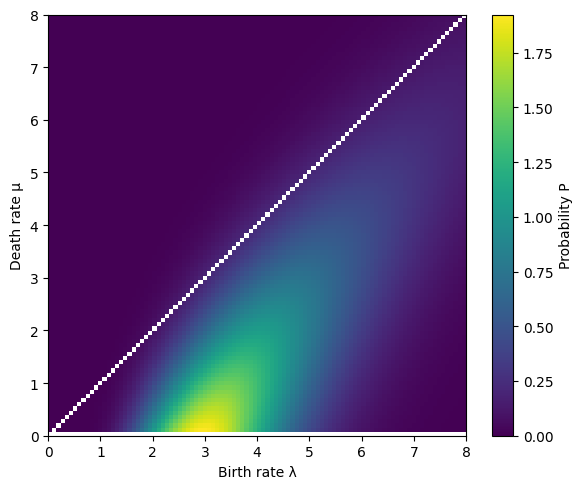

In [62]:
birth_grid = np.linspace(0.0, 8.0, 100)
death_grid = np.linspace(0.0, 8.0, 100)

L = likelihood_grid(
    birth_grid,
    death_grid,
    cell_lineage_T=cell_lineage_T,
    diff_T=diff_T
)
# print(L)
plot_likelihood_surface(birth_grid, death_grid, L)


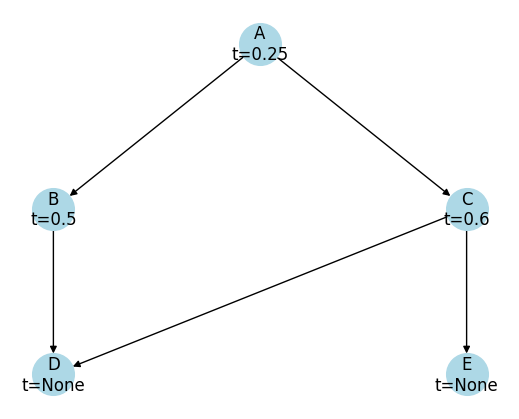

In [4]:
import string

diff_map_edges = [
    ("A", "B"),
    ("A", "C"),
    ("B", "D"),
    ("C", "D"),
    ("C", "E"),
]

diff_times = [0.25, 0.5, 0.60, None, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [5]:
from simulator import load_tree
T, root = load_tree("../data/simulation/test_diff/T_extant.json")

In [6]:
cell_lineage_T = nx.DiGraph()
for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])

In [15]:
for n in T.nodes(data=True):
    if n[1]['event'] == 'sample':
        cell_lineage_T.nodes[n[0]]['type'] = n[1]['type']

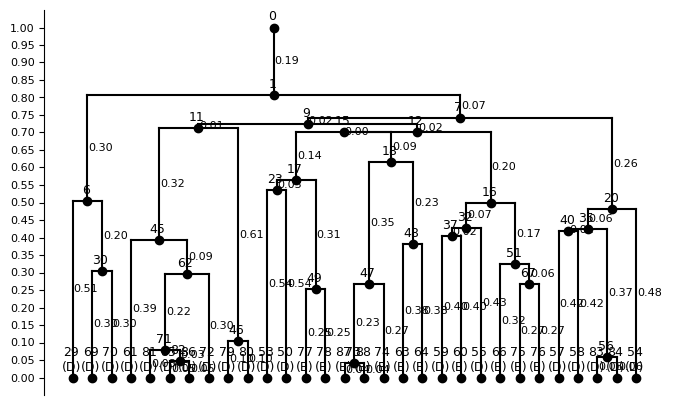

In [16]:
from plotters import draw_ultrametric_tree
draw_ultrametric_tree(cell_lineage_T, root)

In [17]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [22]:
from likelihood import calculate_likelihood

calculate_likelihood(
    {}, {}, 1, pd.DataFrame(), cell_lineage_T, diff_T
)


30 69
30 70
6 29
6 30
82 85
82 86
71 81
71 82
62 71
62 72
45 61
45 62
46 79
46 80
11 45
11 46
23 53
23 50
49 77
49 78
17 23
17 49
73 87
73 88
47 73
47 74
48 63
48 64
18 47
18 48
15 17
15 18
37 59
37 60
32 37
32 55
67 75
67 76
51 66
51 67
16 32
16 51
12 15
12 16
9 11
9 12
40 57
40 58
56 83
56 84
35 40
35 56
20 35
20 54
7 9
7 20
1 6
1 7
0 1
